In [28]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

X_scaled successfully created! Shape: (114000, 9)


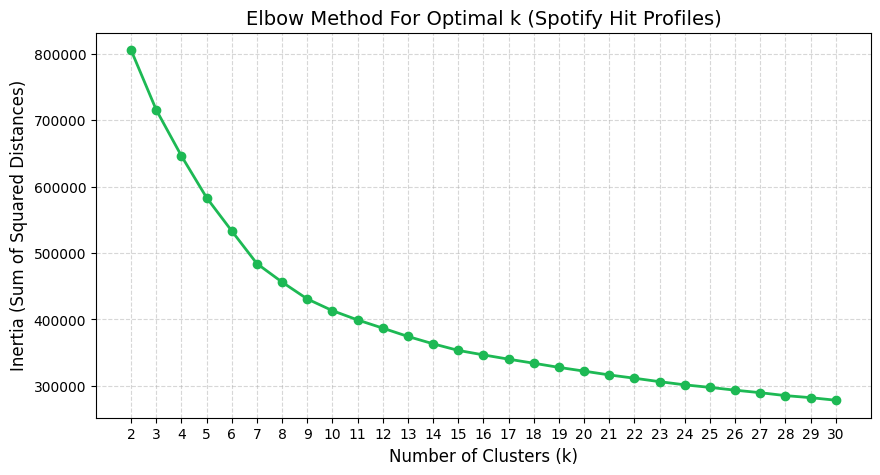

In [29]:
import pandas as pd

# Load dataset
df = pd.read_csv('/content/spotify-tracks-dataset-detailed.csv')

# Defining features
feature_cols = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
]
X = df[feature_cols].fillna(0)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("X_scaled successfully created! Shape:", X_scaled.shape)

# Elbow Method loop
inertias = []
k_range = range(2, 31)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

# 4. Plot the Elbow Curve
plt.figure(figsize=(10, 5))
plt.plot(k_range, inertias, marker='o', color='#1DB954', linewidth=2)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Inertia (Sum of Squared Distances)', fontsize=12)
plt.title('Elbow Method For Optimal k (Spotify Hit Profiles)', fontsize=14)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [30]:
optimal_k = 5
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)

df['cluster'] = kmeans_final.fit_predict(X_scaled)

print(f"K-Means fitted successfully with k={optimal_k}")
print("\nTrack Distribution across Clusters:")
print(df['cluster'].value_counts().sort_index())

K-Means fitted successfully with k=5

Track Distribution across Clusters:
cluster
0    31540
1     8202
2    41221
3    24648
4     8389
Name: count, dtype: int64


In [31]:
cluster_summary = df.groupby('cluster')[feature_cols].mean()

profile_names = {
    0: "Club & Festival Anthems",
    1: "Intimate Acoustic Ballads",
    2: "Mainstream Radio Pop",
    3: "Ambient & Classical Works",
    4: "Urban Hip-Hop & Rap"
}

cluster_summary.index = [f"Cluster {i}: {profile_names.get(i, 'Unknown')}" for i in cluster_summary.index]

display(cluster_summary.round(3))

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Cluster 0: Club & Festival Anthems,0.482,0.814,-5.927,0.080,0.060,0.230,0.193,0.319,136.846
Cluster 1: Intimate Acoustic Ballads,0.364,0.194,-20.541,0.052,0.823,0.787,0.163,0.190,104.265
Cluster 2: Mainstream Radio Pop,0.696,0.730,-6.399,0.091,0.193,0.055,0.165,0.689,119.872
Cluster 3: Ambient & Classical Works,0.538,0.386,-10.514,0.055,0.666,0.051,0.159,0.397,113.522
Cluster 4: Urban Hip-Hop & Rap,0.533,0.746,-7.533,0.193,0.345,0.064,0.739,0.503,120.896


In [32]:
for cluster_id in range(optimal_k):
    print(f"\n=================== CLUSTER {cluster_id}: {profile_names[cluster_id]} ===================")
    cluster_tracks = df[df['cluster'] == cluster_id]
    sample_size = min(5, len(cluster_tracks))
    samples = cluster_tracks.sample(n=sample_size, random_state=42)

    for idx, track in samples.iterrows():
        track_name = track.get('track_name', track.get('name', 'Unknown Track'))
        artist_name = track.get('artists', track.get('artist', 'Unknown Artist'))
        print(f" • '{track_name}' by {artist_name} | Tempo: {track['tempo']:.1f} BPM | Energy: {track['energy']:.2f} | Danceability: {track['danceability']:.2f}")


=================== CLUSTER 0: Club & Festival Anthems ===================
 • 'Living Dead Girl' by Rob Zombie | Tempo: 103.0 BPM | Energy: 0.95 | Danceability: 0.52
 • 'Better Than You' by Dead by April | Tempo: 92.6 BPM | Energy: 0.84 | Danceability: 0.45
 • '1993' by Omar S | Tempo: 128.0 BPM | Energy: 0.47 | Danceability: 0.80
 • 'Hé Suzie' by De Doelleazen;Henk Wijngaard | Tempo: 175.0 BPM | Energy: 0.95 | Danceability: 0.63
 • 'It's Gonna Be Alright - Be Smoove Dub' by Jovonn | Tempo: 120.9 BPM | Energy: 0.64 | Danceability: 0.86

=================== CLUSTER 1: Intimate Acoustic Ballads ===================
 • 'Atmosphere' by BLVKSHP | Tempo: 164.8 BPM | Energy: 0.08 | Danceability: 0.10
 • 'Ylang Ylang' by FKJ;((( O ))) | Tempo: 70.0 BPM | Energy: 0.24 | Danceability: 0.58
 • 'The Spirit of God' by Paul Cardall | Tempo: 123.1 BPM | Energy: 0.09 | Danceability: 0.39
 • 'Danse macabre, Op. 40' by Philharmonia Orchestra;Charles Dutoit | Tempo: 112.1 BPM | Energy: 0.19 | Danceabilit